# Vector Database Evaluation

This notebook evaluates the accuracy of embeddings stored in the Supabase database using labeled test pairs.

**Model:** `sentence-transformers/all-mpnet-base-v2` (raw baseline)

**Metrics:**
- Spearman correlation
- ROC-AUC
- F1, Precision, Recall
- Accuracy
- Confusion Matrix

In [ ]:
import subprocess
import json
import numpy as np
import pandas as pd
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    confusion_matrix,
    roc_curve
)
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer
from .autonotebook import tqdm as notebook_tqdm

print("Libraries loaded successfully")

c:\Users\donov\miniconda3\envs\itsm\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries loaded successfully


## 1. Configuration

In [2]:
# Docker configuration
DOCKER_CONTAINER = "supabase-db"

# Test data path
TEST_PAIRS_PATH = "data_new/fixed_test_pairs.json"

# Model name
MODEL_NAME = "sentence-transformers/all-mpnet-base-v2"

print(f"Docker container: {DOCKER_CONTAINER}")
print(f"Test pairs: {TEST_PAIRS_PATH}")
print(f"Model: {MODEL_NAME}")

Docker container: supabase-db
Test pairs: data_new/fixed_test_pairs.json
Model: sentence-transformers/all-mpnet-base-v2


## 2. Load Test Pairs

In [3]:
# Load test pairs
with open(TEST_PAIRS_PATH, 'r') as f:
    test_data = json.load(f)

texts1 = test_data['texts1']
texts2 = test_data['texts2']
labels = np.array(test_data['labels'])

print(f"Loaded {len(labels)} test pairs")
print(f"Positive pairs: {np.sum(labels == 1.0)}")
print(f"Negative pairs: {np.sum(labels == 0.0)}")
print(f"Label distribution: {np.bincount(labels.astype(int))}")

Loaded 1000 test pairs
Positive pairs: 500
Negative pairs: 500
Label distribution: [500 500]


## 3. Extract Ticket Numbers from Test Pairs

In [4]:
import re

def extract_ticket_number(text):
    """Extract INC ticket number from text."""
    match = re.search(r'INC\d+', text)
    if match:
        return match.group(0)
    return None

# Extract ticket numbers from test pairs
ticket_numbers_1 = [extract_ticket_number(t) for t in texts1]
ticket_numbers_2 = [extract_ticket_number(t) for t in texts2]

print(f"Ticket numbers extracted from texts1: {sum(1 for t in ticket_numbers_1 if t is not None)}/{len(ticket_numbers_1)}")
print(f"Ticket numbers extracted from texts2: {sum(1 for t in ticket_numbers_2 if t is not None)}/{len(ticket_numbers_2)}")

# Show sample
print("\nSample ticket numbers:")
for i in range(min(5, len(ticket_numbers_1))):
    print(f"  Pair {i}: {ticket_numbers_1[i]} <-> {ticket_numbers_2[i]} (label: {labels[i]})")

Ticket numbers extracted from texts1: 1000/1000
Ticket numbers extracted from texts2: 1000/1000

Sample ticket numbers:
  Pair 0: INC0020661 <-> INC0038333 (label: 1)
  Pair 1: INC0035424 <-> INC0011516 (label: 1)
  Pair 2: INC0055060 <-> INC0062441 (label: 1)
  Pair 3: INC0048617 <-> INC0046692 (label: 1)
  Pair 4: INC0054820 <-> INC0041236 (label: 1)


## 4. Load Model

In [5]:
print(f"Loading model: {MODEL_NAME}...")
model = SentenceTransformer(MODEL_NAME)
print("Model loaded successfully")

Loading model: sentence-transformers/all-mpnet-base-v2...
Model loaded successfully


## 5. Query Database for Embeddings

We'll query the database to get embeddings for tickets in our test pairs.

In [6]:
def query_embedding_from_db(ticket_number):
    """Query embedding from database for a ticket number."""
    if ticket_number is None:
        return None
    
    sql = f"""
    SELECT embedding::text 
    FROM incident_tickets 
    WHERE number = '{ticket_number}' 
    LIMIT 1;
    """
    
    result = subprocess.run(
        ['docker', 'exec', DOCKER_CONTAINER, 'psql', '-U', 'postgres', '-t', '-c', sql],
        capture_output=True,
        text=True
    )
    
    if result.returncode == 0 and result.stdout.strip():
        # Parse the vector string [1.0, 2.0, ...] into numpy array
        vector_str = result.stdout.strip()
        vector_str = vector_str.strip('[]')
        if vector_str:
            embedding = np.array([float(x) for x in vector_str.split(',')])
            return embedding
    
    return None

# Test query
test_ticket = ticket_numbers_1[0] if ticket_numbers_1[0] else ticket_numbers_2[0]
if test_ticket:
    test_emb = query_embedding_from_db(test_ticket)
    if test_emb is not None:
        print(f"Successfully retrieved embedding for {test_ticket}")
        print(f"Embedding shape: {test_emb.shape}")
        print(f"Embedding sample (first 5 dims): {test_emb[:5]}")
    else:
        print(f"Failed to retrieve embedding for {test_ticket}")
else:
    print("No valid ticket number found in test pairs")

Successfully retrieved embedding for INC0020661
Embedding shape: (768,)
Embedding sample (first 5 dims): [-0.01637476 -0.0591003   0.02283931  0.03044761 -0.008033  ]


## 6. Compute Similarity Scores

We'll compute cosine similarity between pairs using embeddings from the database.

In [7]:
from sklearn.metrics.pairwise import cosine_similarity

print("Computing similarity scores from database embeddings...")

db_similarities = []
valid_pairs = []
valid_labels = []
missing_count = 0

for i in tqdm(range(len(labels)), desc="Querying embeddings"):
    ticket1 = ticket_numbers_1[i]
    ticket2 = ticket_numbers_2[i]
    
    # Query embeddings from database
    emb1 = query_embedding_from_db(ticket1)
    emb2 = query_embedding_from_db(ticket2)
    
    if emb1 is not None and emb2 is not None:
        # Compute cosine similarity
        similarity = cosine_similarity([emb1], [emb2])[0][0]
        db_similarities.append(similarity)
        valid_pairs.append(i)
        valid_labels.append(labels[i])
    else:
        missing_count += 1

db_similarities = np.array(db_similarities)
valid_labels = np.array(valid_labels)

print(f"\nComputed similarities for {len(db_similarities)} pairs")
print(f"Missing embeddings: {missing_count} pairs")
print(f"Coverage: {len(db_similarities) / len(labels) * 100:.2f}%")

Computing similarity scores from database embeddings...


Querying embeddings: 100%|██████████| 1000/1000 [04:56<00:00,  3.38it/s]


Computed similarities for 1000 pairs
Missing embeddings: 0 pairs
Coverage: 100.00%


## 7. Compute Model Metrics

In [8]:
# Compute Spearman correlation
spearman_corr, _ = spearmanr(valid_labels, db_similarities)

# Compute ROC-AUC
roc_auc = roc_auc_score(valid_labels, db_similarities)

# Find optimal threshold for F1
thresholds = np.arange(0.0, 1.0, 0.01)
f1_scores = []

for thresh in thresholds:
    pred_labels = (db_similarities >= thresh).astype(int)
    f1 = f1_score(valid_labels, pred_labels)
    f1_scores.append(f1)

best_threshold = thresholds[np.argmax(f1_scores)]
best_f1 = max(f1_scores)

# Compute metrics at best threshold
pred_labels = (db_similarities >= best_threshold).astype(int)
precision = precision_score(valid_labels, pred_labels)
recall = recall_score(valid_labels, pred_labels)
accuracy = accuracy_score(valid_labels, pred_labels)
cm = confusion_matrix(valid_labels, pred_labels)

print("="*60)
print("EVALUATION RESULTS - DATABASE EMBEDDINGS")
print("="*60)
print(f"Model: {MODEL_NAME}")
print(f"Test pairs evaluated: {len(valid_labels)}")
print(f"\nMetrics:")
print(f"  Spearman Correlation: {spearman_corr:.4f}")
print(f"  ROC-AUC:              {roc_auc:.4f}")
print(f"  Best F1 Score:        {best_f1:.4f}")
print(f"  Best Threshold:       {best_threshold:.4f}")
print(f"  Precision:            {precision:.4f}")
print(f"  Recall:               {recall:.4f}")
print(f"  Accuracy:             {accuracy:.4f}")
print(f"\nConfusion Matrix:")
print(f"  [[TN={cm[0,0]}, FP={cm[0,1]}],")
print(f"   [FN={cm[1,0]}, TP={cm[1,1]}]]")
print("="*60)

EVALUATION RESULTS - DATABASE EMBEDDINGS
Model: sentence-transformers/all-mpnet-base-v2
Test pairs evaluated: 1000

Metrics:
  Spearman Correlation: 0.4169
  ROC-AUC:              0.7407
  Best F1 Score:        0.6862
  Best Threshold:       0.3500
  Precision:            0.6925
  Recall:               0.6800
  Accuracy:             0.6890

Confusion Matrix:
  [[TN=349, FP=151],
   [FN=160, TP=340]]


## 8. Visualizations

Saved visualization to vectordb_evaluation_results.png


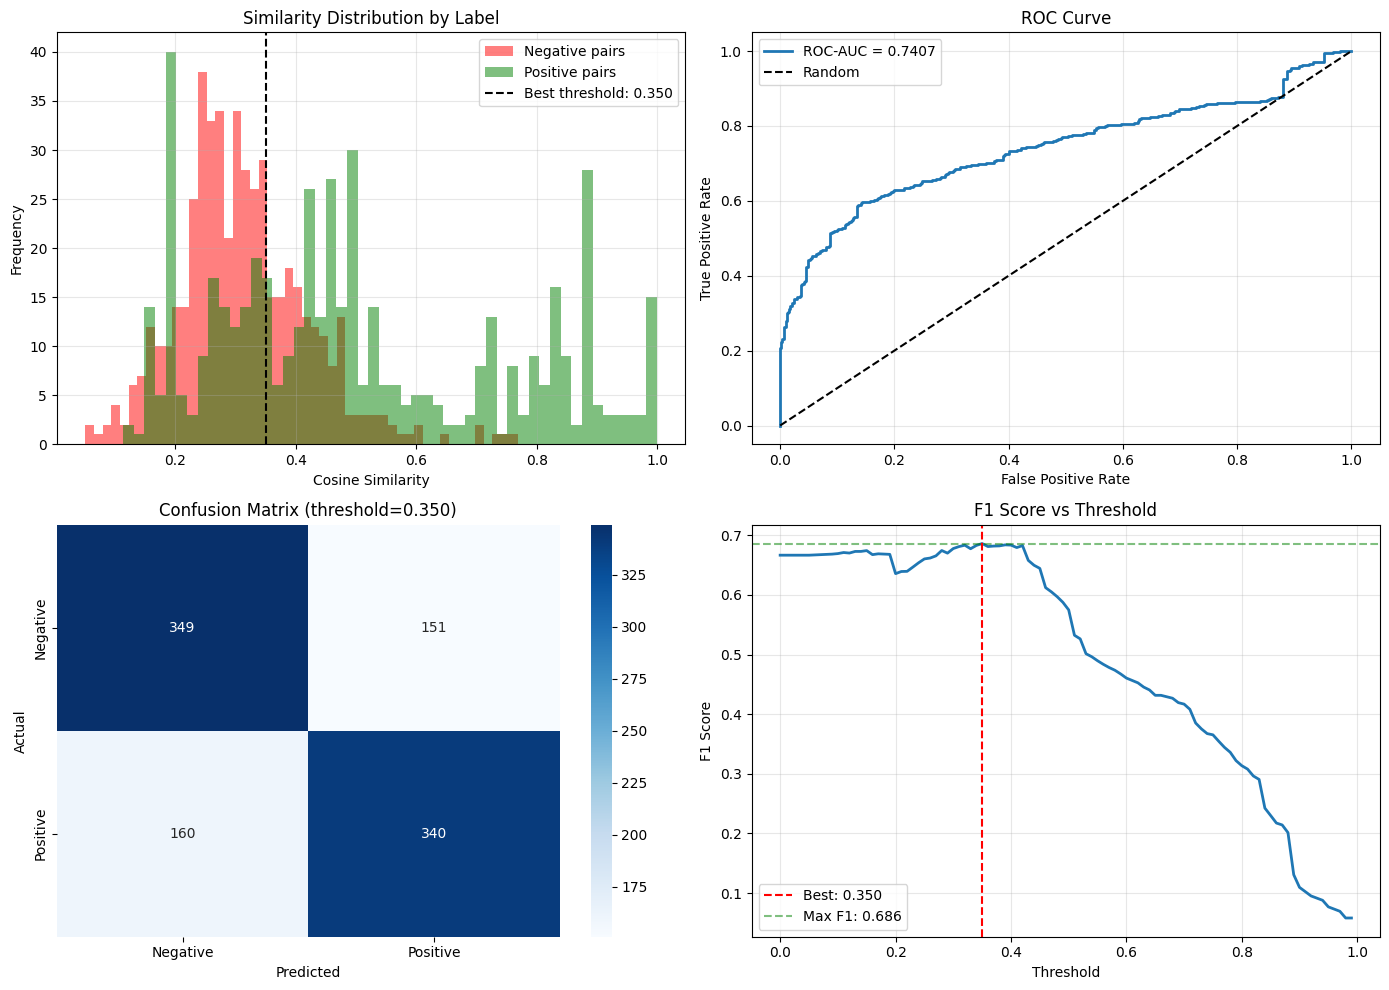

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Similarity Distribution by Label
ax1 = axes[0, 0]
ax1.hist(db_similarities[valid_labels == 0], bins=50, alpha=0.5, label='Negative pairs', color='red')
ax1.hist(db_similarities[valid_labels == 1], bins=50, alpha=0.5, label='Positive pairs', color='green')
ax1.axvline(best_threshold, color='black', linestyle='--', label=f'Best threshold: {best_threshold:.3f}')
ax1.set_xlabel('Cosine Similarity')
ax1.set_ylabel('Frequency')
ax1.set_title('Similarity Distribution by Label')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. ROC Curve
ax2 = axes[0, 1]
fpr, tpr, _ = roc_curve(valid_labels, db_similarities)
ax2.plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.4f}', linewidth=2)
ax2.plot([0, 1], [0, 1], 'k--', label='Random')
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('ROC Curve')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Confusion Matrix
ax3 = axes[1, 0]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax3,
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'])
ax3.set_xlabel('Predicted')
ax3.set_ylabel('Actual')
ax3.set_title(f'Confusion Matrix (threshold={best_threshold:.3f})')

# 4. F1 Score vs Threshold
ax4 = axes[1, 1]
ax4.plot(thresholds, f1_scores, linewidth=2)
ax4.axvline(best_threshold, color='red', linestyle='--', label=f'Best: {best_threshold:.3f}')
ax4.axhline(best_f1, color='green', linestyle='--', alpha=0.5, label=f'Max F1: {best_f1:.3f}')
ax4.set_xlabel('Threshold')
ax4.set_ylabel('F1 Score')
ax4.set_title('F1 Score vs Threshold')
ax4.legend()
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('vectordb_evaluation_results.png', dpi=300, bbox_inches='tight')
print("Saved visualization to vectordb_evaluation_results.png")
plt.show()

## 9. Comparison: Database vs Fresh Model Embeddings

Let's compare the database embeddings with freshly generated embeddings to ensure consistency.

In [10]:
print("Generating fresh embeddings for comparison...")

# Generate fresh embeddings for a sample of pairs
sample_size = min(100, len(valid_pairs))
sample_indices = np.random.choice(valid_pairs, sample_size, replace=False)

fresh_similarities = []
db_similarities_sample = []

for idx in tqdm(sample_indices, desc="Comparing embeddings"):
    # Get original texts
    text1 = texts1[idx]
    text2 = texts2[idx]
    
    # Generate fresh embeddings
    emb1_fresh = model.encode(text1, normalize_embeddings=True)
    emb2_fresh = model.encode(text2, normalize_embeddings=True)
    
    # Compute fresh similarity
    sim_fresh = cosine_similarity([emb1_fresh], [emb2_fresh])[0][0]
    fresh_similarities.append(sim_fresh)
    
    # Get DB embeddings
    ticket1 = ticket_numbers_1[idx]
    ticket2 = ticket_numbers_2[idx]
    emb1_db = query_embedding_from_db(ticket1)
    emb2_db = query_embedding_from_db(ticket2)
    
    if emb1_db is not None and emb2_db is not None:
        sim_db = cosine_similarity([emb1_db], [emb2_db])[0][0]
        db_similarities_sample.append(sim_db)

fresh_similarities = np.array(fresh_similarities)
db_similarities_sample = np.array(db_similarities_sample)

# Compute correlation between fresh and DB similarities
if len(fresh_similarities) == len(db_similarities_sample):
    correlation = np.corrcoef(fresh_similarities, db_similarities_sample)[0, 1]
    mae = np.mean(np.abs(fresh_similarities - db_similarities_sample))
    
    print(f"\nComparison Results (n={len(fresh_similarities)}):")
    print(f"  Correlation (fresh vs DB): {correlation:.4f}")
    print(f"  Mean Absolute Error:       {mae:.6f}")
    print(f"  Max Difference:            {np.max(np.abs(fresh_similarities - db_similarities_sample)):.6f}")
    
    if correlation > 0.99:
        print("\n  Status: EXCELLENT - Database embeddings match fresh embeddings")
    elif correlation > 0.95:
        print("\n  Status: GOOD - Minor differences detected")
    else:
        print("\n  Status: WARNING - Significant differences detected")

Generating fresh embeddings for comparison...


Comparing embeddings: 100%|██████████| 100/100 [00:35<00:00,  2.85it/s]


Comparison Results (n=100):
  Correlation (fresh vs DB): 0.9564
  Mean Absolute Error:       0.062853
  Max Difference:            0.235684

  Status: GOOD - Minor differences detected


## 10. Sample Predictions

Let's look at some sample predictions to understand model behavior.

In [11]:
# Show top 5 true positives (correctly identified similar pairs)
tp_mask = (valid_labels == 1) & (pred_labels == 1)
tp_indices = np.where(tp_mask)[0]
tp_scores = db_similarities[tp_mask]
top_tp = tp_indices[np.argsort(tp_scores)[-5:]]

print("="*80)
print("TOP 5 TRUE POSITIVES (Correctly identified similar pairs)")
print("="*80)
for i, idx in enumerate(top_tp[::-1], 1):
    original_idx = valid_pairs[idx]
    print(f"\n{i}. Similarity: {db_similarities[idx]:.4f}")
    print(f"   Ticket 1: {ticket_numbers_1[original_idx]}")
    print(f"   Text 1: {texts1[original_idx][:100]}...")
    print(f"   Ticket 2: {ticket_numbers_2[original_idx]}")
    print(f"   Text 2: {texts2[original_idx][:100]}...")

# Show top 5 false positives (incorrectly identified as similar)
fp_mask = (valid_labels == 0) & (pred_labels == 1)
fp_indices = np.where(fp_mask)[0]
if len(fp_indices) > 0:
    fp_scores = db_similarities[fp_mask]
    top_fp = fp_indices[np.argsort(fp_scores)[-5:]]
    
    print("\n" + "="*80)
    print("TOP 5 FALSE POSITIVES (Incorrectly identified as similar)")
    print("="*80)
    for i, idx in enumerate(top_fp[::-1], 1):
        original_idx = valid_pairs[idx]
        print(f"\n{i}. Similarity: {db_similarities[idx]:.4f}")
        print(f"   Ticket 1: {ticket_numbers_1[original_idx]}")
        print(f"   Text 1: {texts1[original_idx][:100]}...")
        print(f"   Ticket 2: {ticket_numbers_2[original_idx]}")
        print(f"   Text 2: {texts2[original_idx][:100]}...")

TOP 5 TRUE POSITIVES (Correctly identified similar pairs)

1. Similarity: 0.9995
   Ticket 1: INC0059805
   Text 1: INC0059805 Dear Team

Error occurred while processing the EDI transaction

Interface
Subsidiary     ...
   Ticket 2: INC0068878
   Text 2: INC0068878 Dear Team

Error occurred while processing the EDI transaction

Interface
Subsidiary     ...

2. Similarity: 0.9993
   Ticket 1: INC0060007
   Text 1: INC0060007 Dear Team

Error occurred while processing the EDI transaction. Please find the details b...
   Ticket 2: INC0061094
   Text 2: INC0061094 Dear Team

Error occurred while processing the EDI transaction. Please find the details b...

3. Similarity: 0.9993
   Ticket 1: INC0060876
   Text 1: INC0060876 Dear Team

Error occurred while processing the EDI transaction. Please find the details b...
   Ticket 2: INC0061011
   Text 2: INC0061011 Dear Team

Error occurred while processing the EDI transaction. Please find the details b...

4. Similarity: 0.9993
   Ticket 1: INC

## 11. Save Results

In [12]:
from datetime import datetime

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

# Save evaluation results
results = {
    'model': MODEL_NAME,
    'source': 'database_embeddings',
    'timestamp': timestamp,
    'test_pairs_file': TEST_PAIRS_PATH,
    'total_pairs': len(labels),
    'evaluated_pairs': len(valid_labels),
    'coverage': len(valid_labels) / len(labels),
    'metrics': {
        'spearman_correlation': float(spearman_corr),
        'roc_auc': float(roc_auc),
        'best_f1': float(best_f1),
        'best_threshold': float(best_threshold),
        'precision': float(precision),
        'recall': float(recall),
        'accuracy': float(accuracy),
        'confusion_matrix': cm.tolist()
    }
}

output_file = f"vectordb_evaluation_{timestamp}.json"
with open(output_file, 'w') as f:
    json.dump(results, f, indent=2)

print(f"Results saved to {output_file}")

# Save detailed predictions
predictions_df = pd.DataFrame({
    'pair_index': valid_pairs,
    'ticket_1': [ticket_numbers_1[i] for i in valid_pairs],
    'ticket_2': [ticket_numbers_2[i] for i in valid_pairs],
    'true_label': valid_labels,
    'similarity_score': db_similarities,
    'predicted_label': pred_labels,
    'correct': (valid_labels == pred_labels)
})

predictions_file = f"vectordb_predictions_{timestamp}.csv"
predictions_df.to_csv(predictions_file, index=False)
print(f"Predictions saved to {predictions_file}")

Results saved to vectordb_evaluation_20251228_020742.json
Predictions saved to vectordb_predictions_20251228_020742.csv


## 12. Summary

This evaluation shows:
- How well the database embeddings perform on labeled test pairs
- Optimal threshold for classification
- Consistency between database and fresh embeddings
- Examples of correct and incorrect predictions

**Next Steps:**
1. Compare with fine-tuned model performance (from [models/results/](models/results/))
2. Analyze false positives/negatives to identify improvement areas
3. Test hybrid search combining vector + keyword search